# 参照: Calamity の方法のゲインマップ

> **このノートブックは参照用です。** ゲインマップは `../GainMap.ipynb`(ピークにガウス関数を当てて決める)で作ります。
> ここでは研究室のプログラム **Calamity**(`TPC_caldata/Calamity_v5.0`)と同じ手順で作り、比べられるようにしています。
> $K_a$, $K_b$ の意味は `../GainMap.ipynb` の冒頭にあります。

Calamity の手順:

| 手順 | 中身 |
|---|---|
| ① 1 ヒットのスペクトル | 電荷が正の FADC チャンネルが、アノード・カソードとも 1 本だけのイベントで、そのアノードのチャンネルの電荷を、組ごとに詰める |
| ② ピーク探し | 40 ビンずつまとめ(1 ビン 80 pC)、250〜5000 pC で `TSpectrum` を使い、ピークがちょうど 2 本見つかるまで sigma と threshold を変えて探す |
| ③ 対応づけ | 見つかった 2 本を電荷の大きい順に、30.85 keV と 8.04 keV に対応させる |
| ④ 較正 | 原点 (0, 0) を加えた 3 点に直線を当てて $K_a$(傾き)、$K_b$(切片)を求める。**ピークの位置は `TSpectrum` が見つけたビンの位置そのもの**(ガウス関数は当てない)。χ² のマップを見て、おかしい組はピークの位置を手で直す |
| ⑤ 確認(`Fit`) | 較正したスペクトルの 30.85 keV のピークにガウス関数を当て、平均・σ・分解能のマップを描く($K_a$, $K_b$ には使わない) |
| ⑥ 保存 | `アノード ch  カソード ch  Ka  Kb` の 144 行を書き出す(このノートブックでは `Calibration_Ba133_2017_thr20_calamity.dat`) |

結果(11 run、閾値 20 ADU): 143 / 144 組を較正。上の 7 組は 20171219/Per01 を含めた 12 run のときに手で直したもので、11 run では χ² > 5 の組がさらに 24 組あります(参照用なので直していません)。
⑤ のガウス関数が 30.85 keV のピークに当たったのは 143 組中 98 組で、残りの組は別の山を拾っていました(7 節)。

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials_caldata" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

## 1. データの準備

Ba-133 の較正データ(`TPC_caldata/20171219`、`20171220`、合計約 190 GB)は、研究室の NAS の EricaNext_try のデータの置き場
(`/mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+`、`config/ericanext_config.py` の `DATA_DIR`)の `TPC_caldata/` にあります。
設定ファイルの `{tpc_caldata}` がこの場所になるので、NAS を読める計算機では何もしなくても動きます。
NAS へのつなぎ方(宇宙線研究室の hikaru / akari サーバーに VPN で接続)は、リポジトリ直下の README の「データの置き場所」にあります。

手元にコピーするときは、同じ並び(`<置き場>/TPC_caldata/20171219/Per08_TPC` など)でコピーし、環境変数 `SMILE2P_DATA` に `<置き場>` を設定します
(実データ・シミュレーションのデータも `<置き場>` から読むようになるので、`../1_DataIO/DataIO_example.ipynb` の 1 節の並びにそろえてください)。

設定ファイル `config/tpc_caldata_2017_Ba133.json` に、使う run の一覧(`runs`)、ピークのエネルギー(`peaks_keV`)、各モジュールのパラメータがあります。

In [2]:
CONFIG = "tpc_caldata_2017_Ba133"
cfg = ec.load(CONFIG)
print("tpc_caldata:", ec.tpc_caldata())
for run in cfg["runs"]:
    path = ec.tpc_caldata() / run
    print("OK     " if path.is_dir() else "MISSING", path)
PEAK_KEV = cfg["peaks_keV"]   # [30.85, 8.04]

tpc_caldata: /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171219/Per08_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171219/Per09_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171219/Per10_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171219/Per12_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171220/Per01_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171220/Per02_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171220/Per03_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171220/Per04_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171220/Per05_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171220/Per06_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_da

## 2. 生データツリーを作る

run ごとに `ReadData → RawTreeWriter` を実行します。ターミナルでは、リポジトリの `run_script` ディレクトリで次を run ごとに実行するのと同じです(例は 20171219/Per08)。

```bash
cd EricaNext_try/run_script
python3 run_chain.py tpc_caldata_2017_Ba133 -o Ba133_20171219_Per08.root --raw --compression 505 \
    --set ReadData.data_dir=<TPC_caldata の場所>/20171219/Per08_TPC
```

| 引数 | 意味 |
|---|---|
| `tpc_caldata_2017_Ba133` | 設定ファイル。`ReadData.TPC_Only = true`(HA なし)、`RawTreeWriter` は波形の最大値がベースライン + 10 ADU 以下のチャンネルを保存しない・ヒットと HA は保存しない |
| `--set ReadData.data_dir=...` | run のディレクトリ(設定ファイルの値を上書き) |
| `--raw --compression 505` | 生データツリーだけを zstd で書く |

1 つの run に読み出していないボードの空のファイルがあっても、ReadData は自動で飛ばします。
**時間と大きさの目安:** 全 run で数時間、合計約 40 GB(大きい run は 20171220/Per06)。出力が既にある run は再実行しません。

In [3]:
RAWS = []
for run in cfg["runs"]:
    date, name = run.split("/")
    out = CACHE / f"Ba133_{date}_{name.replace('_TPC', '')}.root"
    cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(out), "--raw", "--compression", "505",
           "--set", f"ReadData.data_dir={ec.tpc_caldata() / run}"]
    if not out.exists():
        print(" ".join(cmd))
        r = subprocess.run(cmd, capture_output=True, text=True)
        if r.returncode != 0:
            print(r.stdout[-3000:], r.stderr[-3000:])
        r.check_returncode()
    RAWS.append(out)
print(len(RAWS), "runs")

11 runs


## 3. 設定

| 変数 | 意味 | 値 |
|---|---|---|
| `THRESHOLD` | 電荷を積分するサンプルの閾値 [ADU](CalcFADC の既定) | 20 |
| `REBIN` | ピーク探しのときにまとめるビンの数(Calamity の既定) | 40(2 pC × 40 = 80 pC) |
| `SEARCH` | ピークを探す電荷の範囲 [pC](Calamity の既定) | 250〜5000 |

In [4]:
THRESHOLD = 20.0
REBIN = 40
SEARCH = (250., 5000.)
MIN_EVENTS = 200          # これより 1 ヒットのイベントが少ない組は較正しない

## 4. 1 ヒットのスペクトル

下の C++ の関数で、波形から CalcFADC と同じ電荷 [pC] を計算し(`../1_DataIO/modules/2_CalcFADC/`)、1 ヒットのイベントを選びます。

- **チャンネルの番号:** 1 つの run に一部のボードしか無いとき、生データツリーの `fadc_ch` は「その run の何番目のボードか」で振られています。
  `run_info` のボード ID(1 始まり)を使って、物理的なチャンネル(アノード 0–11、カソード 12–23)に直します(`charges_phys`)。
- **1 ヒット:** 電荷が正のチャンネルが、アノード 12 本中 1 本、カソード 12 本中 1 本だけのイベント(SMILE_tool_box の CalcFADC の `SPEC_1Hit`)。
  詰めるのはアノードの電荷です(ゲインマップはアノードの電荷に掛けるため)。
- ヒストグラムは CalcFADC の `SPEC_1Hit` と同じ 5000 ビン(−100.5〜9899.5 pC、1 ビン 2 pC)。

全 run で数十分かかります。結果は `cache/Ba133_2017_spec1hit_thr20.root` に保存し、次からはそれを読みます。

In [5]:
ROOT.gInterpreter.Declare(r"""
// CalcFADC の電荷 [pC] を物理的なチャンネル(アノード 0-11、カソード 12-23)で返す
ROOT::RVecD charges_phys(const ROOT::RVec<short>& ch, const ROOT::RVec<short>& wave, double thr,
                         const ROOT::RVecI& amap, const ROOT::RVecI& cmap) {
  ROOT::RVecD q(24, -100. * 0.8);
  for (size_t i = 0; i < ch.size(); i++) {
    const short* w = &wave[i * 512];
    double mean = 0;
    for (int k = 0; k < 30; k++) mean += (double)w[k];
    mean /= 30;
    double c = 0; int n = 0;
    for (int k = 30; k < 500; k++)
      if ((double)w[k] - mean > thr) { c += (double)w[k] - mean; n++; }
    if (n == 0) c = -100;
    const int side = ch[i] / 12, idx = (ch[i] % 12) / 4, k4 = ch[i] % 4;
    const int board = side ? cmap[idx] : amap[idx];   // 0 始まりの物理的なボード
    q[12 * side + 4 * board + k4] = c * 2. * 20. / 50.;
  }
  return q;
}
// 1 ヒット: 電荷が正のチャンネルがアノード 1 本・カソード 1 本だけ -> {アノード ch, カソード ch, アノードの電荷}
ROOT::RVecD one_hit(const ROOT::RVecD& q) {
  int na = 0, nc = 0, ia = -1, ic = -1;
  for (int i = 0; i < 12; i++) {
    if (q[i] > 0) { na++; ia = i; }
    if (q[12 + i] > 0) { nc++; ic = i; }
  }
  if (na != 1 || nc != 1) return {-1., -1., 0.};
  return {double(ia), double(ic), q[ia]};
}
""")

SPEC_FILE = CACHE / f"Ba133_2017_spec1hit_thr{THRESHOLD:g}.root"
if not SPEC_FILE.exists():
    total = ROOT.TH2D("spec", "pair = 12 * anode + cathode;pair;anode charge [pC]", 144, -0.5, 143.5, 5000, -100.5, 9899.5)
    for i, f in enumerate(RAWS):
        info = ROOT.RDataFrame("RawTreeWriter/run_info", str(f)).AsNumpy(["anode_ids", "cathode_ids"])
        amap = ",".join(str(int(x) - 1) for x in info["anode_ids"][0])
        cmap = ",".join(str(int(x) - 1) for x in info["cathode_ids"][0])
        d = (ROOT.RDataFrame("RawTreeWriter/raw", str(f))
               .Define("q", f"charges_phys(fadc_ch, fadc_wave, {THRESHOLD}, ROOT::RVecI{{{amap}}}, ROOT::RVecI{{{cmap}}})")
               .Define("h", "one_hit(q)").Filter("h[0] >= 0")
               .Define("pair", "h[0] * 12 + h[1]").Define("qa", "h[2]"))
        h = d.Histo2D((f"spec{i}", "", 144, -0.5, 143.5, 5000, -100.5, 9899.5), "pair", "qa").GetValue()
        print(f.name, " boards: anode", amap, " cathode", cmap, " 1-hit events", int(h.GetEntries()))
        total.Add(h)
    fout = ROOT.TFile(str(SPEC_FILE), "recreate"); total.Write(); fout.Close()
spec_file = ROOT.TFile.Open(str(SPEC_FILE))
SPEC = spec_file.Get("spec")

def spectrum(a, c):
    """アノード ch a × カソード ch c の 1 ヒットのスペクトル(TH1D、2 pC / ビン)"""
    b = a * 12 + c + 1
    return SPEC.ProjectionY(f"SPEC_1Hit_A{a}_C{c}", b, b)

counts = np.array([[spectrum(a, c).GetEntries() for c in range(12)] for a in range(12)])
print("1-hit events:", int(counts.sum()))

1-hit events: 1920465


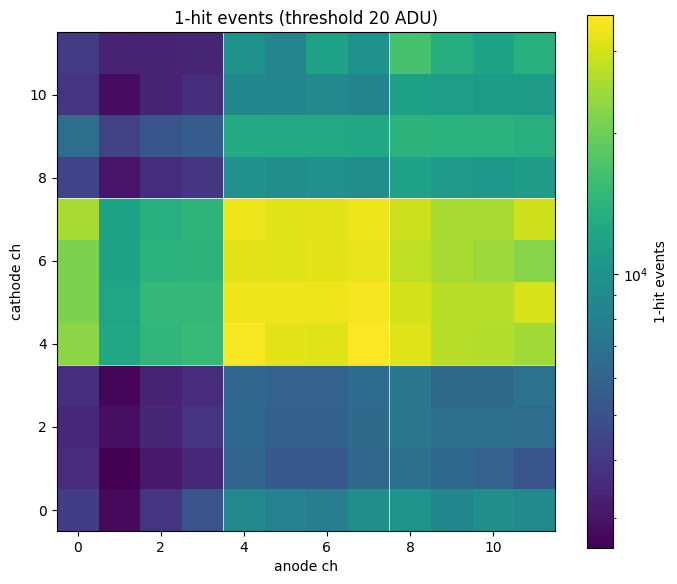

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
m = ax.imshow(counts.T, origin="lower", cmap="viridis", norm="log")
fig.colorbar(m, ax=ax, label="1-hit events")
ax.set_xlabel("anode ch"); ax.set_ylabel("cathode ch"); ax.set_title(f"1-hit events (threshold {THRESHOLD:g} ADU)")
for b in (3.5, 7.5):
    ax.axvline(b, color="w", lw=0.5); ax.axhline(b, color="w", lw=0.5)   # ボードの境目
fig.tight_layout()

## 5. ピーク探し

Calamity の `Peak_Search1` と同じ手順です。

1. スペクトルを `REBIN` ビンずつまとめ、`SEARCH` の範囲の外を 0 にする
2. `TSpectrum::Search(h, sigma, "nodraw", 1 - 0.5^n)` でピークを探す。見つかった数が多すぎたら n を 2 倍(閾値を上げる)、少なすぎたら 1/3 にする(100 回まで)。
   それでも 2 本にならなければ sigma を 2 倍または 1/3 にしてやり直す(10 回まで)
3. 見つかったピークを電荷の大きい順に並べる

In [7]:
def peak_search(h, n_peak):
    """Calamity Peak_Search1: n_peak 本のピークの位置 [pC] を大きい順に返す"""
    t = h.Clone(h.GetName() + "_search")
    t.Rebin(REBIN)
    for n in range(t.GetNbinsX()):
        if t.GetBinCenter(n) < SEARCH[0] or t.GetBinCenter(n) > SEARCH[1]:
            t.SetBinContent(n, 0.0)
    sp = ROOT.TSpectrum()
    sigma, thre, thre_n, found = 1., 0.5, 1., 0
    for _ in range(10):
        for _ in range(100):
            found = sp.Search(t, sigma, "nodraw goff", 1 - thre ** thre_n)
            if found == n_peak: break
            thre_n = thre_n * 2 if found > n_peak else thre_n / 3
        if found == n_peak: break
        sigma = sigma * 2 if found > n_peak else sigma / 3
    return sorted([sp.GetPositionX()[i] for i in range(found)], reverse=True)

peaks = {}
for a in range(12):
    for c in range(12):
        if counts[a, c] >= MIN_EVENTS:
            peaks[(a, c)] = peak_search(spectrum(a, c), len(PEAK_KEV))
n_ok = sum(1 for p in peaks.values() if len(p) == len(PEAK_KEV))
print(f"{len(peaks)} pairs with >= {MIN_EVENTS} events, {n_ok} with {len(PEAK_KEV)} peaks")

144 pairs with >= 200 events, 144 with 2 peaks


## 6. 較正($K_a$, $K_b$)

原点 (0, 0) と、2 本のピーク(電荷の大きい方 = 30.85 keV、小さい方 = 8.04 keV)の 3 点に直線 `pol1` を当てます(Calamity の `Calibration`)。
χ² が大きい組は、ピークの取り違えなどが疑われます。

In [8]:
MANUAL_PEAKS = {
    # (アノード ch, カソード ch): [30.85 keV のピーク [pC], 8.04 keV のピーク [pC]]   χ² がおかしい組を、図を見て手で直す
    # 自動のピーク探しが別の山を拾った組(20171219/Per01 を含めた 12 run、閾値 20 ADU のスペクトルを 20 pC のビンで見て決めた。精度は ±50〜100 pC)
    (1, 1):  [1950., 580.],
    (1, 10): [1750., 540.],
    (2, 1):  [1930., 540.],
    (7, 0):  [1700., 430.],
    (7, 2):  [1550., 400.],
    (8, 0):  [1800., 430.],
    (1, 0):  [],               # 30.85 keV のピークが見えない -> 較正しない(0 を書く)
}

def calibrate(q_peaks):
    """原点 + ピークに pol1 -> (Ka, Kb, chi2)"""
    x = np.array([0.] + list(q_peaks)); y = np.array([0.] + list(PEAK_KEV))
    g = ROOT.TGraph(len(x), x, y)
    f = ROOT.TF1("cal_pol1", "pol1", 0, 6000)
    f.SetParameters(0, 0.01)
    g.Fit(f, "Q", "", 0, 6000)
    return f.GetParameter(1), f.GetParameter(0), f.GetChisquare()

cal = {}
for key, p in peaks.items():
    p = MANUAL_PEAKS.get(key, p)
    if len(p) == len(PEAK_KEV):
        cal[key] = calibrate(p)
print(len(cal), "pairs calibrated")

143 pairs calibrated


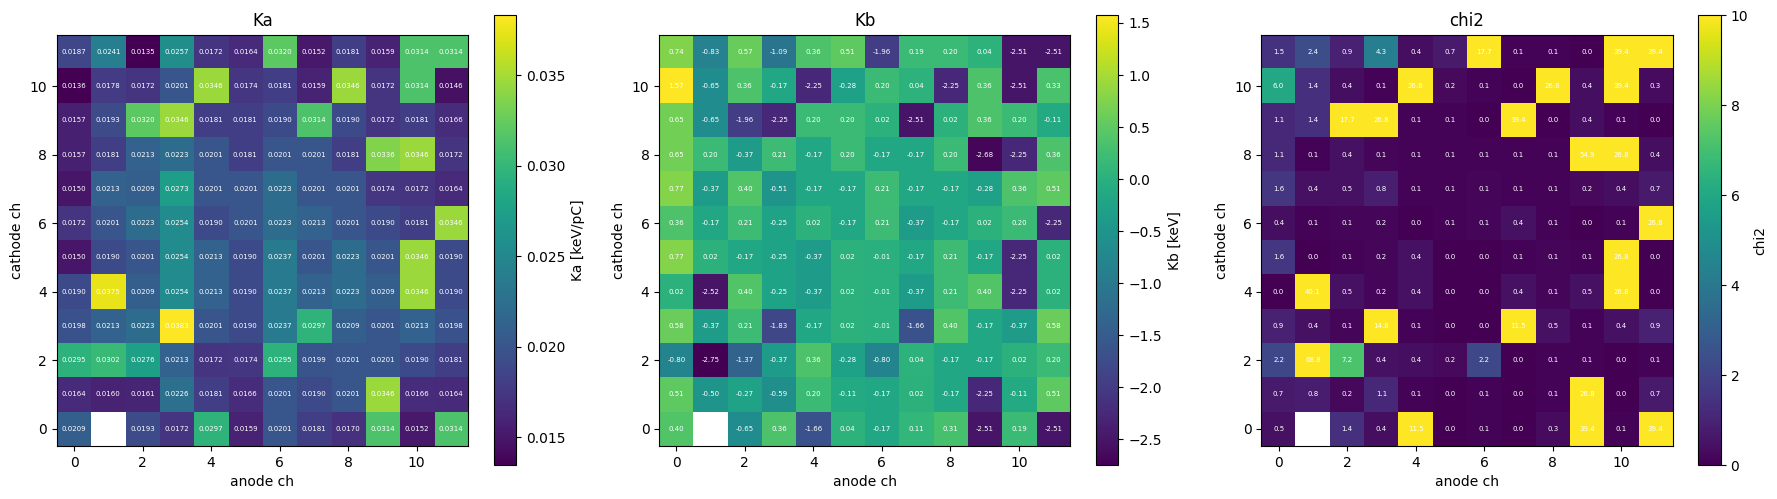

In [9]:
def pair_map(values, title, label, ax, fmt="{:.3g}", **kw):
    z = np.full((12, 12), np.nan)
    for (a, c), v in values.items():
        z[a, c] = v
    m = ax.imshow(z.T, origin="lower", cmap="viridis", **kw)
    plt.colorbar(m, ax=ax, label=label)
    for (a, c), v in values.items():
        ax.text(a, c, fmt.format(v), ha="center", va="center", fontsize=5, color="w")
    ax.set_xlabel("anode ch"); ax.set_ylabel("cathode ch"); ax.set_title(title)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
pair_map({k: v[0] for k, v in cal.items()}, "Ka", "Ka [keV/pC]", ax[0], "{:.4f}")
pair_map({k: v[1] for k, v in cal.items()}, "Kb", "Kb [keV]", ax[1], "{:.2f}")
pair_map({k: v[2] for k, v in cal.items()}, "chi2", "chi2", ax[2], "{:.1f}", vmin=0, vmax=10)
fig.tight_layout()

χ² の大きい組のスペクトルと、見つかったピークを確認します。ピークの取り違えがあれば、上のセルの `MANUAL_PEAKS` にその組の正しいピークの位置を書いて、
6 節のセルから実行し直します(Calamity の GUI で印を動かして「目分量」で直す操作にあたります)。ピークが読めない組は `[]` にすると較正しません。

20171219/Per01 を含めた 12 run(閾値 20 ADU)では、自動のピーク探しで 7 組が χ² > 5 になりました(A1C0, A1C1, A1C10, A2C1, A7C0, A7C2, A8C0)。
どれも 1 ヒットのイベントが 4000〜12000 と少ない組です。図で見ると 30.85 keV のピークは 1500〜2000 pC にあり、自動では別の山を拾っていました。
A1C0 以外の 6 組は図で読んだ位置を `MANUAL_PEAKS` に書き、A1C0 は 30.85 keV のピークが見えないので較正していません。
下の図は、`MANUAL_PEAKS` で直した後のピークの位置(赤の点線)です。

chi2 > 5.0 または 2 本見つからなかった組: 24 [(0, 10), (1, 2), (1, 4), (2, 2), (2, 9), (3, 3), (3, 9), (4, 0), (4, 10), (6, 11), (7, 3), (7, 9), (8, 10), (9, 0), (9, 1), (9, 8), (10, 4), (10, 5), (10, 8), (10, 10), (10, 11), (11, 0), (11, 6), (11, 11)]
MANUAL_PEAKS で直した組: [(1, 0), (1, 1), (1, 10), (2, 1), (7, 0), (7, 2), (8, 0)]


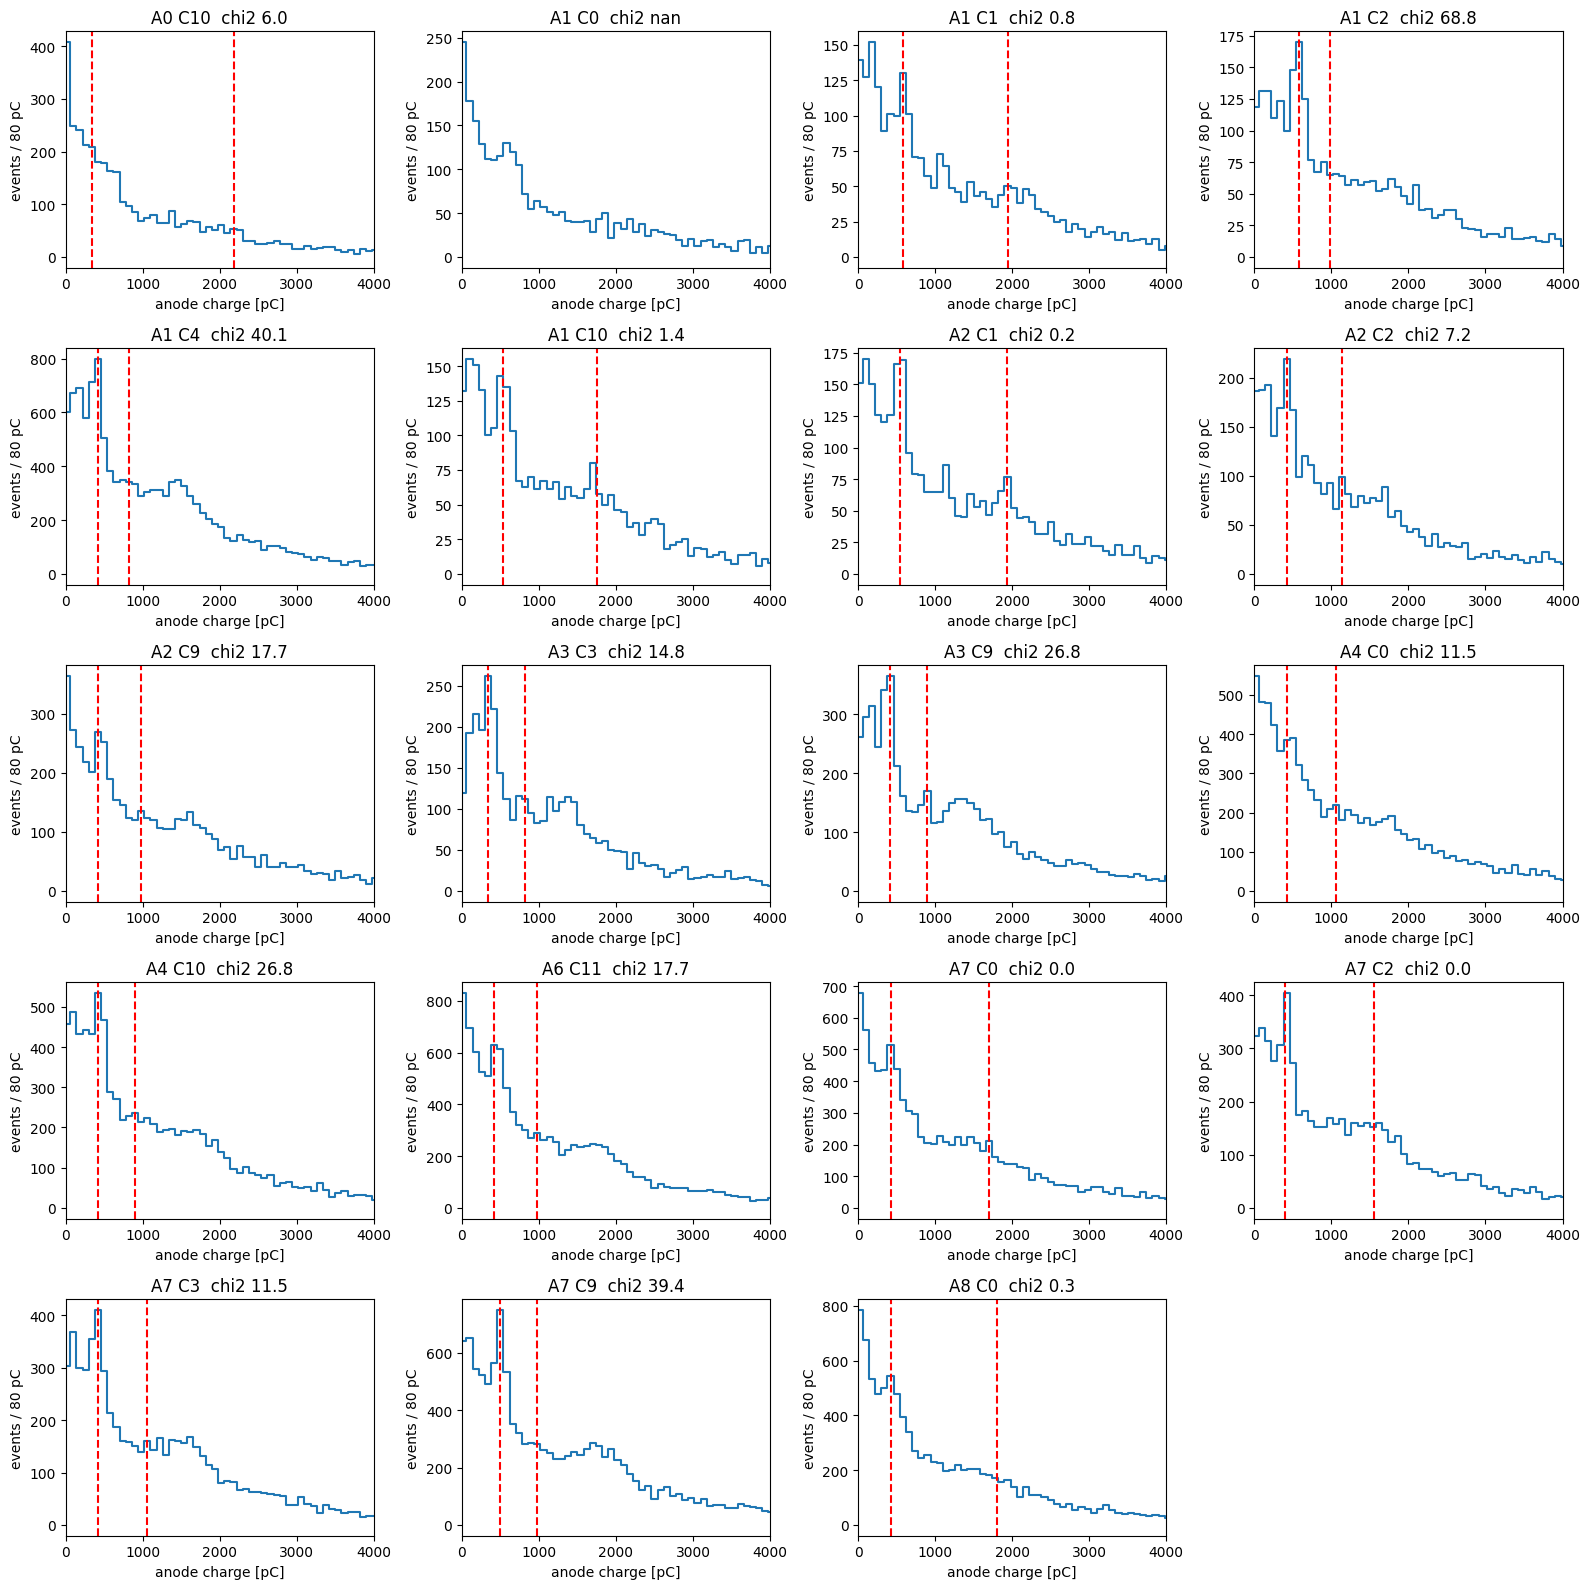

In [10]:
CHI2_MAX = 5.
bad = sorted([k for k, v in cal.items() if v[2] > CHI2_MAX] + [k for k, p in peaks.items() if len(p) != len(PEAK_KEV)])
print(f"chi2 > {CHI2_MAX} または 2 本見つからなかった組: {len(bad)}", bad[:30])
print("MANUAL_PEAKS で直した組:", sorted(MANUAL_PEAKS))
show = sorted(set(bad[:12]) | set(MANUAL_PEAKS)) or sorted(cal)[:6]
nrow = int(np.ceil(len(show) / 4))
fig, ax = plt.subplots(nrow, 4, figsize=(16, 3.2 * nrow), squeeze=False)
for a_, (a, c) in zip(ax.flat, show):
    h = spectrum(a, c); h.Rebin(REBIN)
    x = [h.GetBinCenter(i) for i in range(1, h.GetNbinsX() + 1)]
    y = [h.GetBinContent(i) for i in range(1, h.GetNbinsX() + 1)]
    a_.step(x, y, where="mid")
    for xp in MANUAL_PEAKS.get((a, c), peaks.get((a, c), [])):
        a_.axvline(xp, color="r", ls="--")
    chi = cal[(a, c)][2] if (a, c) in cal else float("nan")
    a_.set_xlim(0, 4000); a_.set_title(f"A{a} C{c}  chi2 {chi:.1f}")
    a_.set_xlabel("anode charge [pC]"); a_.set_ylabel(f"events / {2 * REBIN} pC")
for a_ in ax.flat[len(show):]:
    a_.axis("off")
fig.tight_layout()

## 7. ガウス関数のフィット(Calamity の `Fit`)

較正ができたら、Calamity と同じく、各組のスペクトルを $E = K_a q + K_b$ で keV に直し、30.85 keV のピークにガウス関数を当てて確かめます
(Calamity の `Fit`。$K_a$, $K_b$ を決めるのには使わない)。

1. 2 pC のビンのスペクトルの各ビンを $K_a q + K_b$ [keV] に移して詰め直し、`FIT_REBIN`(8)ビンずつまとめる
2. 平均 30.85 keV、σ = 30.85 × 0.1 keV から始め、平均 − 0.7 √平均 〜 平均 + 1.2 √平均 [keV] の範囲で `gaus` を当てる
3. 求まった平均と σ を初期値・範囲の中心にして、もう 5 回当て直す

| 変数 | 意味 | 値(Calamity の既定) |
|---|---|---|
| `FIT_REBIN` | keV のスペクトルでまとめるビンの数 | 8 |
| `FIT_MIN`, `FIT_MAX` | フィットの範囲: 平均 − `FIT_MIN` √平均 〜 平均 + `FIT_MAX` √平均 [keV] | 0.7, 1.2 |

In [11]:
FIT_REBIN = 8
FIT_MIN, FIT_MAX = 0.7, 1.2
FIT_PEAK = PEAK_KEV[0]          # 30.85 keV

def fit_gauss(a, c):
    # Calamity Fit: keV のスペクトルの 30.85 keV のピークに gaus -> (定数 [events / ビン], 平均 [keV], σ [keV], ビンの幅 [keV])
    ka, kb = cal[(a, c)][:2]
    h = spectrum(a, c)
    kev = ROOT.TH1F(f"Energy_A{a}_C{c}", "", h.GetNbinsX(), ka * h.GetXaxis().GetXmin() + kb, ka * h.GetXaxis().GetXmax() + kb)
    for j in range(1, h.GetNbinsX() + 1):
        kev.Fill(ka * h.GetBinCenter(j) + kb, h.GetBinContent(j))
    kev.Rebin(FIT_REBIN)
    f = ROOT.TF1(f"fit_gaus_A{a}_C{c}", "gaus", 0, 60)
    f.SetParameters(500, FIT_PEAK, FIT_PEAK * 0.1)
    kev.Fit(f, "Q0", "", FIT_PEAK - np.sqrt(FIT_PEAK) * FIT_MIN, FIT_PEAK + np.sqrt(FIT_PEAK) * FIT_MAX)
    for _ in range(5):
        m, sg = f.GetParameter(1), f.GetParameter(2)
        if not m > 0:
            break
        f.SetParameter(1, m); f.SetParameter(2, sg)
        kev.Fit(f, "Q0", "", m - np.sqrt(m) * FIT_MIN, m + np.sqrt(m) * FIT_MAX)
    return f.GetParameter(0), f.GetParameter(1), abs(f.GetParameter(2)), kev.GetBinWidth(1)

gfit = {k: fit_gauss(*k) for k in sorted(cal)}

# ガウス関数が 30.85 keV のピークに当たったか: 平均が 25〜36 keV、FWHM が 150 % 以下
FIT_OK_MEAN, FIT_OK_FWHM = (25., 36.), 150.
def fit_ok(v):
    return FIT_OK_MEAN[0] < v[1] < FIT_OK_MEAN[1] and v[2] / v[1] * 235 < FIT_OK_FWHM
good = {k: v for k, v in gfit.items() if fit_ok(v)}
fail = sorted(k for k in gfit if k not in good)
print(f"ガウス関数が当たった組: {len(good)} / {len(gfit)}  (平均の中央値 {np.median([v[1] for v in good.values()]):.2f} keV, "
      f"FWHM の中央値 {np.median([v[2] / v[1] * 235 for v in good.values()]):.0f} %)")
print(f"当たらなかった組: {len(fail)}", fail)

ガウス関数が当たった組: 98 / 143  (平均の中央値 30.01 keV, FWHM の中央値 55 %)
当たらなかった組: 45 [(0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 9), (0, 10), (1, 1), (1, 2), (1, 3), (1, 4), (2, 0), (2, 2), (2, 9), (2, 11), (3, 0), (3, 1), (3, 2), (3, 3), (3, 9), (3, 10), (4, 0), (4, 2), (4, 10), (6, 0), (6, 2), (6, 10), (6, 11), (7, 0), (7, 9), (8, 0), (8, 2), (8, 3), (8, 10), (9, 0), (9, 8), (10, 5), (10, 10), (10, 11), (11, 0), (11, 1), (11, 6), (11, 11)]


全部の組のスペクトルです(Calamity のキャンバスと同じ並び: 横がアノード ch、縦がカソード ch で上が 11)。
赤の点線が較正に使ったピークの位置(`MANUAL_PEAKS` で直した組はその位置)、黒の線が 30.85 keV に当てたガウス関数です。
ガウス関数は keV で当てたものを $q = (E - K_b) / K_a$ で pC に戻し、ビンの幅の比を掛けて重ねています(フィットの範囲だけ描く)。

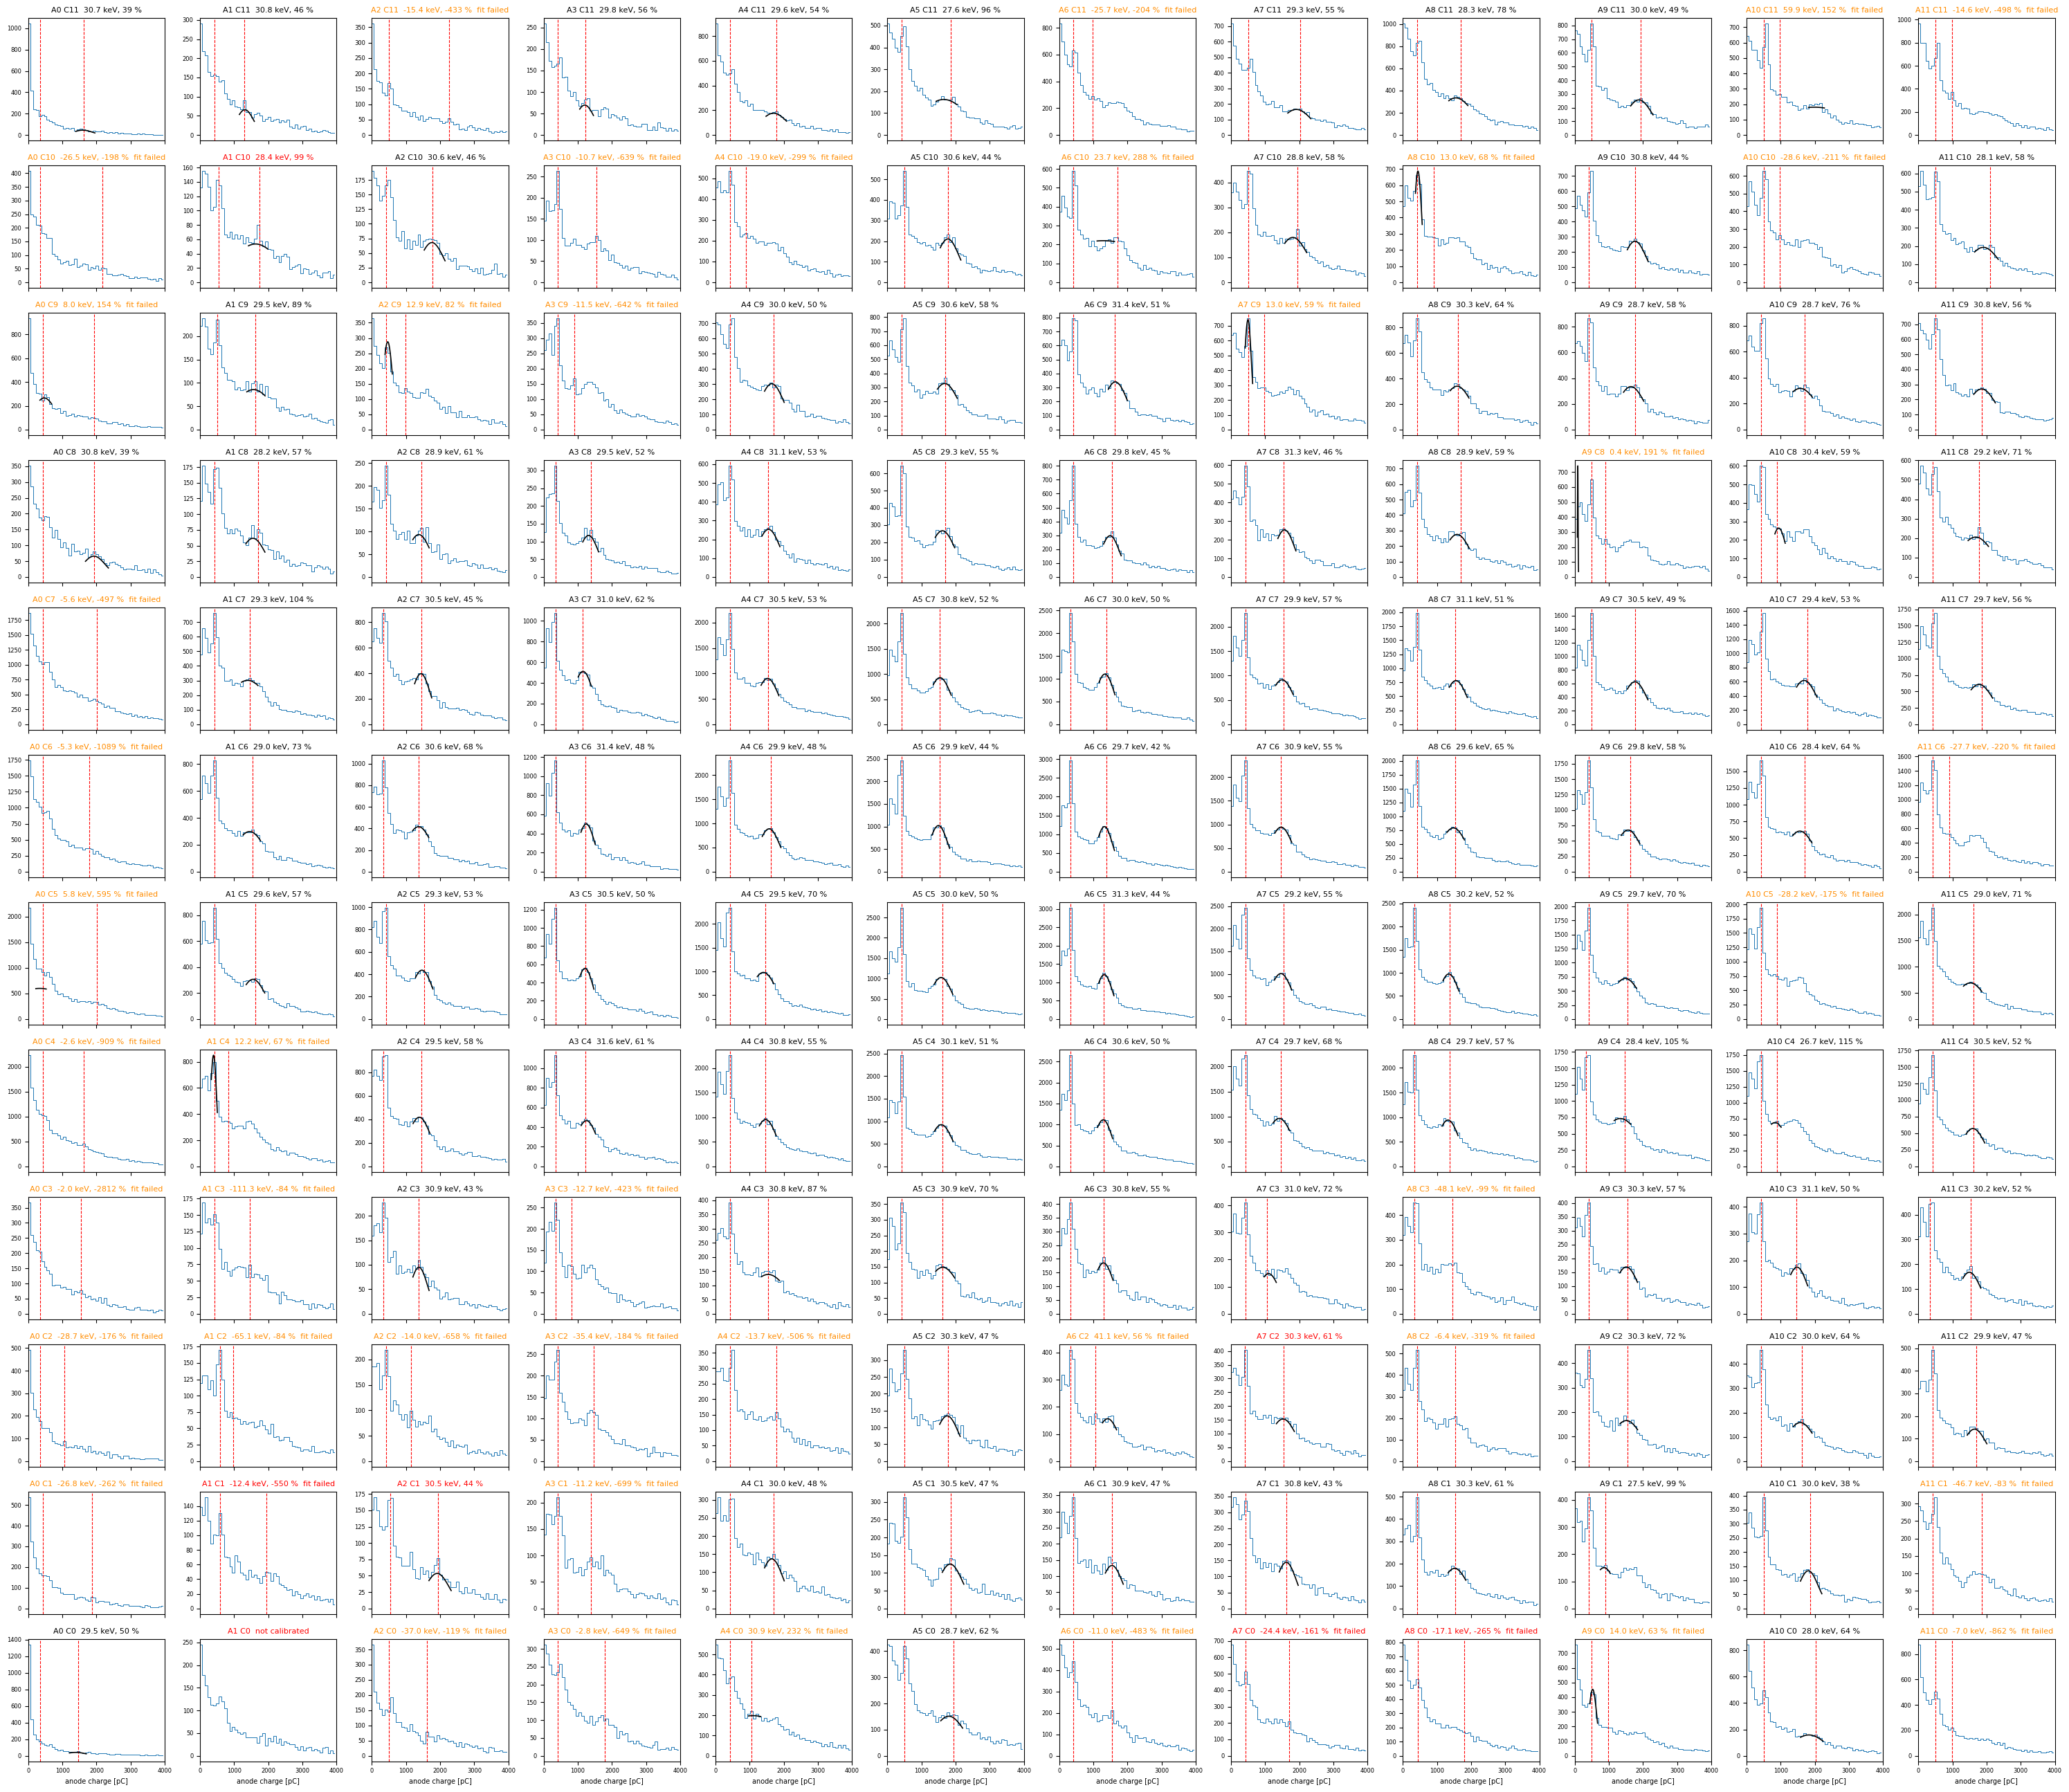

In [12]:
fig, ax = plt.subplots(12, 12, figsize=(30, 26), sharex=True)
for a in range(12):
    for c in range(12):
        a_ = ax[11 - c, a]
        h = spectrum(a, c); h.Rebin(REBIN)
        x = np.array([h.GetBinCenter(i) for i in range(1, h.GetNbinsX() + 1)])
        y = np.array([h.GetBinContent(i) for i in range(1, h.GetNbinsX() + 1)])
        m = x < 4000
        a_.step(x[m], y[m], where="mid", lw=0.7)
        for xp in MANUAL_PEAKS.get((a, c), peaks.get((a, c), [])):
            a_.axvline(xp, color="r", ls="--", lw=0.8)
        if (a, c) in gfit:
            ka, kb = cal[(a, c)][:2]
            const, mu, sg, wk = gfit[(a, c)]
            e = np.linspace(mu - np.sqrt(mu) * FIT_MIN, mu + np.sqrt(mu) * FIT_MAX, 100) if mu > 0 else np.array([])
            q = (e - kb) / ka
            # keV のビン(幅 wk keV = wk / ka pC)あたりの数 -> この図のビン(2 * REBIN pC)あたりの数
            a_.plot(q, const * np.exp(-0.5 * ((e - mu) / sg) ** 2) * (2 * REBIN) / (wk / ka), "k", lw=1.2)
            title = f"A{a} C{c}  {mu:.1f} keV, {sg / mu * 235:.0f} %" + ("" if (a, c) in good else "  fit failed")
        else:
            title = f"A{a} C{c}  not calibrated"
        color = "r" if (a, c) in MANUAL_PEAKS else ("darkorange" if (a, c) in fail else "k")
        a_.set_title(title, fontsize=8, color=color)
        a_.tick_params(labelsize=6); a_.set_xlim(0, 4000)
for a in range(12):
    ax[11, a].set_xlabel("anode charge [pC]", fontsize=7)
fig.tight_layout()

タイトルはガウス関数の平均と分解能(FWHM = 2.35 σ / 平均)です。赤のタイトルは `MANUAL_PEAKS` で直した組、
橙のタイトル(`fit failed`)はガウス関数が 30.85 keV のピークに当たらなかった組(平均が 25〜36 keV の外か、FWHM が 150 % より大きい)です。
平均が 30.85 keV に近いほど、較正の直線がピークをよく通っています。

ガウス関数が当たらなかった組は、スペクトルに 30.85 keV のピークがほとんど見えない組です(アノード 0 の列、カソード 0 と 11 の行など端の ch に多い)。
6 節の χ² は 3 点(原点と 2 本のピーク)に直線を当てたときのものなので、ピーク探しが別の山を拾っても小さくなることがあり、
このフィットで初めて分かります。

平均・σ・分解能の地図(Calamity の `th2_Fit_Mean`, `th2_Fit_Sigma`, `th2_Fit_Reso`):

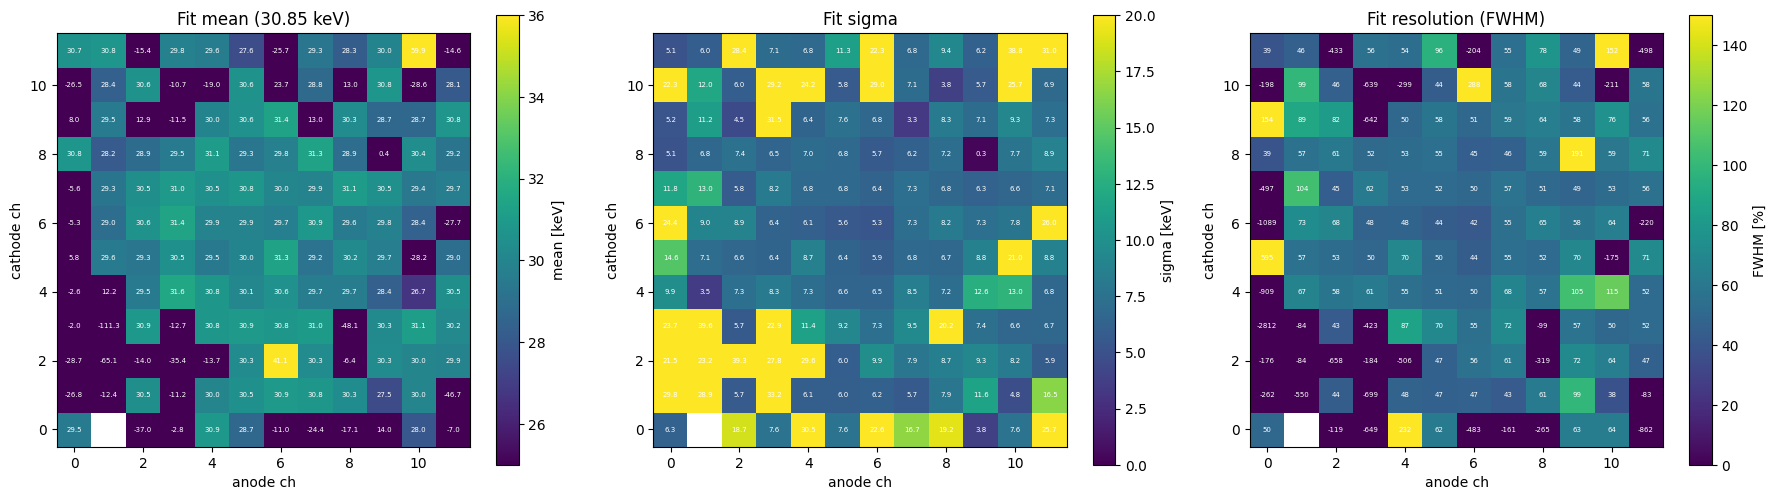

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
# 色の範囲は固定(当たらなかった組の値は範囲の外で端の色になる。数字はそのまま書く)
pair_map({k: v[1] for k, v in gfit.items()}, "Fit mean (30.85 keV)", "mean [keV]", ax[0], "{:.1f}", vmin=25, vmax=36)
pair_map({k: v[2] for k, v in gfit.items()}, "Fit sigma", "sigma [keV]", ax[1], "{:.1f}", vmin=0, vmax=20)
pair_map({k: v[2] / v[1] * 235 for k, v in gfit.items()}, "Fit resolution (FWHM)", "FWHM [%]", ax[2], "{:.0f}", vmin=0, vmax=150)
fig.tight_layout()

## 8. ゲインマップを書き出す

TPC_Calibration が読む形(`アノード ch  カソード ch  Ka  Kb`、カソードの外側のループ、Calamity の `Cal_Save` と同じ並び)で書きます。
較正できなかった組は 0 にします(必要なら `MANUAL_PEAKS` で直してから書き出してください)。

作ったゲインマップを解析に使うときは、`run_chain.py` に `--set TPC_Calibration.ParameterFile=<パス>` を付けるか、設定ファイルの値を書き換えます。

In [14]:
OUT_CAL = CACHE / f"Calibration_Ba133_2017_thr{THRESHOLD:g}_calamity.dat"
with open(OUT_CAL, "w") as fout:
    for c in range(12):
        for a in range(12):
            ka, kb = cal.get((a, c), (0., 0., 0.))[:2]
            fout.write(f" {a}\t{c}\t{ka:g}\t{kb:g}\n")
print("wrote", OUT_CAL, f"({len(cal)} / 144 pairs calibrated)")

wrote /home/onoda/ANLNext/EricaNext_try/tutorials_caldata/cache/Calibration_Ba133_2017_thr20_calamity.dat (143 / 144 pairs calibrated)


## 9. ガス増幅率のマップ

Calamity の `Gain.c` と同じ式で、$K_a$ からガス増幅率を出します。1 keV あたりの電子の数は 1 / W(W = 23.6 eV)、
電子 1 個の電荷は 1.6 × 10⁻⁷ pC、700 はエレキの換算の係数(Calamity のまま)です。

$$ G = \frac{W / e}{K_a} \Big/ 700 = \frac{23.6\times10^{-3}\,\mathrm{keV} / 1.6\times10^{-7}\,\mathrm{pC}}{K_a} \Big/ 700 $$

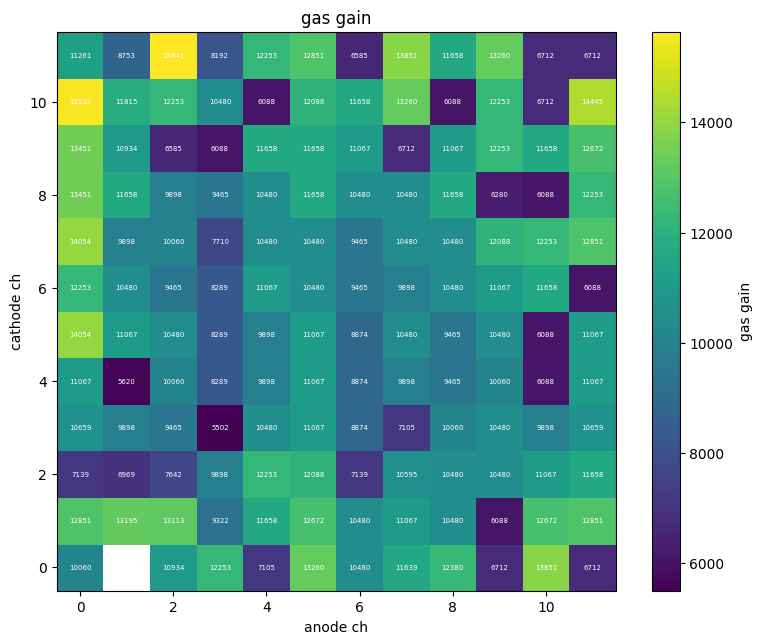

In [15]:
gain = {k: (23.6e-3 / 1.6e-7) / v[0] / 700 for k, v in cal.items() if v[0] > 0}
fig, ax = plt.subplots(figsize=(8, 6.5))
pair_map(gain, "gas gain", "gas gain", ax, "{:.0f}")
fig.tight_layout()